In [2]:
 pip install torch torchvision torchaudio

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: C:\Users\User\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [3]:
# ============================================================
# CELL 1 - IMPORT LIBRARIES
# ============================================================

import os
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve,
    ConfusionMatrixDisplay
)

print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.0+cpu


In [4]:
# ============================================================
# CELL 2 - REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)
print("CUDA available:", torch.cuda.is_available())

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", DEVICE)

Random seed: 42
CUDA available: False
Using device: cpu


In [5]:
# ============================================================
# CELL 3 - PATHS
# ============================================================

BASE_DIR = ".."

FEATURE_FILE = os.path.join(
    BASE_DIR,
    "data",
    "features",
    "landslide_weather_terrain_features.csv"
)

MODEL_DIR = os.path.join(
    BASE_DIR,
    "models"
)

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

print("Feature file:")
print(FEATURE_FILE)

print("\nModel directory:")
print(MODEL_DIR)

Feature file:
..\data\features\landslide_weather_terrain_features.csv

Model directory:
..\models


In [6]:
# ============================================================
# CELL 4 - LOAD DATASET
# ============================================================

df = pd.read_csv(
    FEATURE_FILE,
    parse_dates=["date"]
)

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (192120, 37)


,date,rainfall_mm,rain_mm,rain_hours,temp_max,temp_min,temp_mean,wind_max,wind_gust_max,district,...,month_cos,heavy_rain_10mm,heavy_rain_25mm,heavy_rain_50mm,heavy_rain_100mm,elevation_mean_m,elevation_max_m,elevation_min_m,slope_mean_deg,slope_max_deg
0,1998-01-31,4.2,4.2,15.0,29.3,24.5,26.5,18.6,43.2,Ampara,...,0.866025,0,0,0,0,45.176092,615.203064,-3.557961,3.358947,66.36321
1,1998-02-01,3.6,3.6,11.0,28.6,24.9,26.5,19.6,43.6,Ampara,...,0.500000,0,0,0,0,45.176092,615.203064,-3.557961,3.358947,66.36321
2,1998-02-02,1.5,1.5,8.0,29.1,25.2,26.9,22.7,47.5,Ampara,...,0.500000,0,0,0,0,45.176092,615.203064,-3.557961,3.358947,66.36321
3,1998-02-03,0.0,0.0,0.0,29.0,24.7,26.4,20.5,42.1,Ampara,...,0.500000,0,0,0,0,45.176092,615.203064,-3.557961,3.358947,66.36321
4,1998-02-04,0.2,0.2,2.0,28.9,24.4,26.4,18.7,39.2,Ampara,...,0.500000,0,0,0,0,45.176092,615.203064,-3.557961,3.358947,66.36321


In [7]:
# ============================================================
# CELL 5 - DATASET CHECK
# ============================================================

print("Columns:")
print(df.columns.tolist())

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

print("\nDistricts:")
print(df["district"].nunique())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate district-date rows:")
print(
    df.duplicated(
        subset=["district", "date"]
    ).sum()
)

Columns:
['date', 'rainfall_mm', 'rain_mm', 'rain_hours', 'temp_max', 'temp_min', 'temp_mean', 'wind_max', 'wind_gust_max', 'district', 'latitude', 'longitude', 'landslide_events', 'landslide_recorded', 'rainfall_1day', 'rainfall_3day', 'rainfall_7day', 'rainfall_14day', 'rainfall_30day', 'rainfall_3day_avg', 'rainfall_7day_avg', 'rainfall_14day_avg', 'rainfall_30day_avg', 'temperature_range', 'month', 'day_of_year', 'month_sin', 'month_cos', 'heavy_rain_10mm', 'heavy_rain_25mm', 'heavy_rain_50mm', 'heavy_rain_100mm', 'elevation_mean_m', 'elevation_max_m', 'elevation_min_m', 'slope_mean_deg', 'slope_max_deg']

Date range:
1998-01-31 00:00:00 to 2019-12-31 00:00:00

Districts:
24

Missing values:
0

Duplicate district-date rows:
0


In [8]:
# ============================================================
# CELL 6 - SORT CHRONOLOGICALLY
# ============================================================

df = df.sort_values(
    ["district", "date"]
).reset_index(drop=True)

print("Dataset sorted by district and date.")

Dataset sorted by district and date.


In [9]:
# ============================================================
# CELL 7 - LSTM FEATURES
# ============================================================

LSTM_FEATURES = [
    "rainfall_mm",
    "rain_mm",
    "rain_hours",
    "temp_max",
    "temp_min",
    "temp_mean",
    "wind_max",
    "wind_gust_max",

    "rainfall_1day",
    "rainfall_3day",
    "rainfall_7day",
    "rainfall_14day",
    "rainfall_30day",

    "rainfall_3day_avg",
    "rainfall_7day_avg",
    "rainfall_14day_avg",
    "rainfall_30day_avg",

    "temperature_range",

    "month_sin",
    "month_cos",

    "heavy_rain_10mm",
    "heavy_rain_25mm",
    "heavy_rain_50mm",
    "heavy_rain_100mm",

    "elevation_mean_m",
    "elevation_max_m",
    "elevation_min_m",
    "slope_mean_deg",
    "slope_max_deg"
]

TARGET = "landslide_recorded"

print("Number of LSTM features:", len(LSTM_FEATURES))

Number of LSTM features: 29


In [10]:
# ============================================================
# CELL 8 - FEATURE VALIDATION
# ============================================================

missing_features = [
    feature
    for feature in LSTM_FEATURES
    if feature not in df.columns
]

if len(missing_features) > 0:
    print("Missing features:")
    print(missing_features)
else:
    print("All LSTM features are available.")

All LSTM features are available.


In [11]:
# ============================================================
# CELL 9 - MODEL PERIOD
# ============================================================

MODEL_START = "1998-01-01"
MODEL_END = "2019-12-31"

df = df[
    (df["date"] >= MODEL_START) &
    (df["date"] <= MODEL_END)
].copy()

df = df.sort_values(
    ["district", "date"]
).reset_index(drop=True)

print("LSTM dataset shape:", df.shape)
print("Date range:", df["date"].min(), "to", df["date"].max())

LSTM dataset shape: (192120, 37)
Date range: 1998-01-31 00:00:00 to 2019-12-31 00:00:00


In [12]:
# ============================================================
# CELL 10 - CHRONOLOGICAL SPLIT
# ============================================================

TRAIN_END = "2015-12-31"
VAL_START = "2016-01-01"
VAL_END = "2017-12-31"
TEST_START = "2018-01-01"

train_rows = df[
    df["date"] <= TRAIN_END
].copy()

val_rows = df[
    (df["date"] >= VAL_START) &
    (df["date"] <= VAL_END)
].copy()

test_rows = df[
    df["date"] >= TEST_START
].copy()

print("Training rows:", len(train_rows))
print("Validation rows:", len(val_rows))
print("Test rows:", len(test_rows))

Training rows: 157056
Validation rows: 17544
Test rows: 17520


In [13]:
# ============================================================
# CELL 11 - TARGET DISTRIBUTION
# ============================================================

print("TRAIN:")
print(train_rows[TARGET].value_counts())
print(train_rows[TARGET].value_counts(normalize=True))

print("\nVALIDATION:")
print(val_rows[TARGET].value_counts())
print(val_rows[TARGET].value_counts(normalize=True))

print("\nTEST:")
print(test_rows[TARGET].value_counts())
print(test_rows[TARGET].value_counts(normalize=True))

TRAIN:
landslide_recorded
0    156272
1       784
Name: count, dtype: int64
landslide_recorded
0    0.995008
1    0.004992
Name: proportion, dtype: float64

VALIDATION:
landslide_recorded
0    17529
1       15
Name: count, dtype: int64
landslide_recorded
0    0.999145
1    0.000855
Name: proportion, dtype: float64

TEST:
landslide_recorded
0    17477
1       43
Name: count, dtype: int64
landslide_recorded
0    0.997546
1    0.002454
Name: proportion, dtype: float64


In [14]:
# ============================================================
# CELL 12 - SEQUENCE CONFIGURATION
# ============================================================

SEQUENCE_LENGTH = 14

print(
    "LSTM sequence length:",
    SEQUENCE_LENGTH,
    "days"
)

LSTM sequence length: 14 days


In [15]:
# ============================================================
# CELL 13 - SCALE FEATURES
# ============================================================

scaler = StandardScaler()

scaler.fit(
    train_rows[LSTM_FEATURES]
)

print("Scaler fitted using training data only.")

Scaler fitted using training data only.


In [16]:
# ============================================================
# CELL 14 - TRANSFORM FEATURES
# ============================================================

df_scaled = df.copy()

df_scaled[LSTM_FEATURES] = scaler.transform(
    df_scaled[LSTM_FEATURES]
)

print("Feature scaling completed.")

Feature scaling completed.


In [17]:
# ============================================================
# CELL 14 - TRANSFORM FEATURES
# ============================================================

df_scaled = df.copy()

df_scaled[LSTM_FEATURES] = scaler.transform(
    df_scaled[LSTM_FEATURES]
)

print("Feature scaling completed.")

Feature scaling completed.


In [18]:
# ============================================================
# CELL 15 - CREATE LSTM SEQUENCES
# ============================================================

def create_sequences(
    data,
    feature_columns,
    target_column,
    sequence_length
):

    X_sequences = []
    y_values = []
    dates = []
    districts = []

    for district, group in data.groupby("district"):

        group = group.sort_values("date").reset_index(drop=True)

        feature_values = group[
            feature_columns
        ].values.astype(np.float32)

        target_values = group[
            target_column
        ].values.astype(np.float32)

        date_values = group["date"].values

        for i in range(
            sequence_length,
            len(group)
        ):

            X_sequences.append(
                feature_values[
                    i-sequence_length:i
                ]
            )

            y_values.append(
                target_values[i]
            )

            dates.append(
                date_values[i]
            )

            districts.append(
                district
            )

    return (
        np.array(X_sequences, dtype=np.float32),
        np.array(y_values, dtype=np.float32),
        np.array(dates),
        np.array(districts)
    )


X_all, y_all, dates_all, districts_all = create_sequences(
    df_scaled,
    LSTM_FEATURES,
    TARGET,
    SEQUENCE_LENGTH
)

print("Sequence shape:", X_all.shape)
print("Target shape:", y_all.shape)

Sequence shape: (191784, 14, 29)
Target shape: (191784,)


In [19]:
# ============================================================
# CELL 16 - SPLIT SEQUENCES
# ============================================================

train_mask = dates_all <= np.datetime64(TRAIN_END)

val_mask = (
    (dates_all >= np.datetime64(VAL_START)) &
    (dates_all <= np.datetime64(VAL_END))
)

test_mask = dates_all >= np.datetime64(TEST_START)

X_train_seq = X_all[train_mask]
y_train_seq = y_all[train_mask]

X_val_seq = X_all[val_mask]
y_val_seq = y_all[val_mask]

X_test_seq = X_all[test_mask]
y_test_seq = y_all[test_mask]

dates_train_seq = dates_all[train_mask]
dates_val_seq = dates_all[val_mask]
dates_test_seq = dates_all[test_mask]

districts_train_seq = districts_all[train_mask]
districts_val_seq = districts_all[val_mask]
districts_test_seq = districts_all[test_mask]

print("Training:", X_train_seq.shape)
print("Validation:", X_val_seq.shape)
print("Test:", X_test_seq.shape)

Training: (156720, 14, 29)
Validation: (17544, 14, 29)
Test: (17520, 14, 29)


In [20]:
# ============================================================
# CELL 17 - SEQUENCE TARGET DISTRIBUTION
# ============================================================

print("TRAIN")
print(pd.Series(y_train_seq).value_counts())

print("\nVALIDATION")
print(pd.Series(y_val_seq).value_counts())

print("\nTEST")
print(pd.Series(y_test_seq).value_counts())

TRAIN
0.0    155936
1.0       784
Name: count, dtype: int64

VALIDATION
0.0    17529
1.0       15
Name: count, dtype: int64

TEST
0.0    17477
1.0       43
Name: count, dtype: int64


In [21]:
# ============================================================
# CELL 18 - PYTORCH DATASET
# ============================================================

class LandslideSequenceDataset(Dataset):

    def __init__(self, X, y):

        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.y)

    def __getitem__(self, index):

        return (
            self.X[index],
            self.y[index]
        )


train_dataset = LandslideSequenceDataset(
    X_train_seq,
    y_train_seq
)

val_dataset = LandslideSequenceDataset(
    X_val_seq,
    y_val_seq
)

test_dataset = LandslideSequenceDataset(
    X_test_seq,
    y_test_seq
)

print("Datasets created.")

Datasets created.


In [22]:
# ============================================================
# CELL 19 - DATALOADERS
# ============================================================

BATCH_SIZE = 256

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("DataLoaders ready.")

DataLoaders ready.


In [23]:
# ============================================================
# CELL 20 - CLASS IMBALANCE WEIGHT
# ============================================================

negative_count = np.sum(y_train_seq == 0)
positive_count = np.sum(y_train_seq == 1)

pos_weight_value = (
    negative_count /
    positive_count
)

print("Negative samples:", negative_count)
print("Positive samples:", positive_count)
print("Positive class weight:", pos_weight_value)

pos_weight = torch.tensor(
    [pos_weight_value],
    dtype=torch.float32,
    device=DEVICE
)

Negative samples: 155936
Positive samples: 784
Positive class weight: 198.89795918367346


In [24]:
# ============================================================
# CELL 21 - LSTM MODEL
# ============================================================

class LandslideLSTM(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=64,
        num_layers=2,
        dropout=0.3
    ):

        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_size,
            1
        )

    def forward(self, x):

        output, (hidden, cell) = self.lstm(x)

        last_output = output[:, -1, :]

        last_output = self.dropout(
            last_output
        )

        logits = self.fc(
            last_output
        ).squeeze(1)

        return logits


input_size = len(LSTM_FEATURES)

lstm_model = LandslideLSTM(
    input_size=input_size,
    hidden_size=64,
    num_layers=2,
    dropout=0.3
).to(DEVICE)

print(lstm_model)

LandslideLSTM(
  (lstm): LSTM(29, 64, num_layers=2, batch_first=True, dropout=0.3)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [25]:
# ============================================================
# CELL 22 - LOSS AND OPTIMIZER
# ============================================================

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

print("Loss:", criterion)
print("Optimizer:", optimizer)

Loss: BCEWithLogitsLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 1e-05
)


In [26]:
# ============================================================
# CELL 22 - LOSS AND OPTIMIZER
# ============================================================

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

print("Loss:", criterion)
print("Optimizer:", optimizer)

Loss: BCEWithLogitsLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 1e-05
)


In [27]:
# ============================================================
# CELL 23 - TRAINING FUNCTION
# ============================================================

def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    device
):

    model.train()

    total_loss = 0.0

    for X_batch, y_batch in loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        logits = model(
            X_batch
        )

        loss = criterion(
            logits,
            y_batch
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += (
            loss.item() *
            len(y_batch)
        )

    return total_loss / len(loader.dataset)

In [28]:
# ============================================================
# CELL 24 - VALIDATION FUNCTION
# ============================================================

def evaluate_loss(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    total_loss = 0.0

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(
                X_batch
            )

            loss = criterion(
                logits,
                y_batch
            )

            total_loss += (
                loss.item() *
                len(y_batch)
            )

    return total_loss / len(loader.dataset)

In [29]:
# ============================================================
# CELL 25 - TRAIN LSTM
# ============================================================

EPOCHS = 30
PATIENCE = 5

train_losses = []
val_losses = []

best_val_loss = float("inf")
patience_counter = 0

best_model_path = os.path.join(
    MODEL_DIR,
    "lstm_landslide_best.pth"
)

for epoch in range(1, EPOCHS + 1):

    train_loss = train_one_epoch(
        lstm_model,
        train_loader,
        optimizer,
        criterion,
        DEVICE
    )

    val_loss = evaluate_loss(
        lstm_model,
        val_loader,
        criterion,
        DEVICE
    )

    scheduler.step(val_loss)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.5f} | "
        f"Val Loss: {val_loss:.5f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        patience_counter = 0

        torch.save(
            lstm_model.state_dict(),
            best_model_path
        )

        print("  -> Best model saved.")

    else:

        patience_counter += 1

        if patience_counter >= PATIENCE:

            print(
                "Early stopping triggered."
            )

            break

print("\nTraining completed.")
print("Best validation loss:", best_val_loss)

Epoch 01/30 | Train Loss: 1.03762 | Val Loss: 0.39755
  -> Best model saved.
Epoch 02/30 | Train Loss: 0.94644 | Val Loss: 0.39292
  -> Best model saved.
Epoch 03/30 | Train Loss: 0.92204 | Val Loss: 0.34512
  -> Best model saved.
Epoch 04/30 | Train Loss: 0.86971 | Val Loss: 0.34617
Epoch 05/30 | Train Loss: 0.88778 | Val Loss: 0.33388
  -> Best model saved.
Epoch 06/30 | Train Loss: 0.89511 | Val Loss: 0.35866
Epoch 07/30 | Train Loss: 0.86697 | Val Loss: 0.31458
  -> Best model saved.
Epoch 08/30 | Train Loss: 0.84567 | Val Loss: 0.32323
Epoch 09/30 | Train Loss: 0.85866 | Val Loss: 0.31423
  -> Best model saved.
Epoch 10/30 | Train Loss: 0.83821 | Val Loss: 0.31089
  -> Best model saved.
Epoch 11/30 | Train Loss: 0.82342 | Val Loss: 0.32856
Epoch 12/30 | Train Loss: 0.81999 | Val Loss: 0.33500
Epoch 13/30 | Train Loss: 0.81453 | Val Loss: 0.32029
Epoch 14/30 | Train Loss: 0.75031 | Val Loss: 0.35452
Epoch 15/30 | Train Loss: 0.74094 | Val Loss: 0.36859
Early stopping triggered.

Tr

In [30]:
# ============================================================
# CELL 26 - LOAD BEST MODEL
# ============================================================

lstm_model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=DEVICE
    )
)

lstm_model.eval()

print("Best LSTM model loaded.")

Best LSTM model loaded.


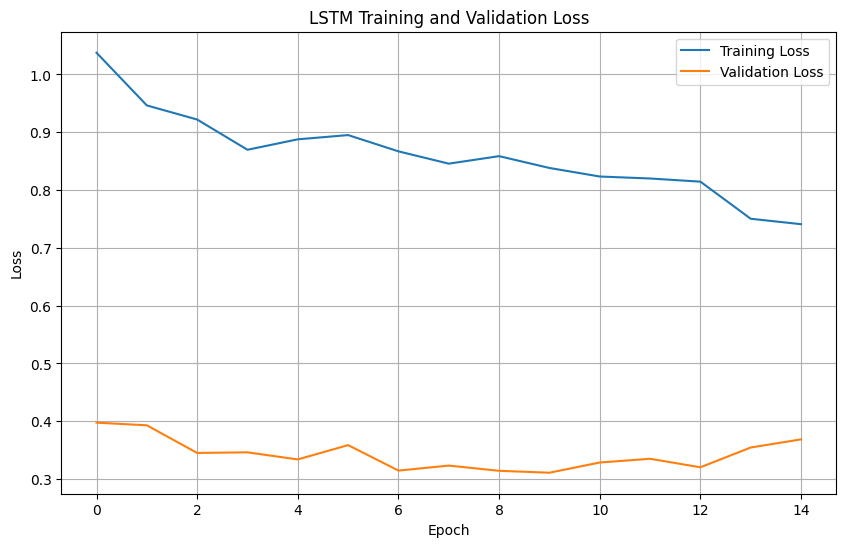

In [31]:
# ============================================================
# CELL 27 - TRAINING CURVES
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

In [32]:
# ============================================================
# CELL 28 - LSTM VALIDATION PREDICTIONS
# ============================================================

def predict_probabilities(
    model,
    loader,
    device
):

    model.eval()

    probabilities = []
    actual = []

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)

            logits = model(
                X_batch
            )

            probs = torch.sigmoid(
                logits
            )

            probabilities.extend(
                probs.cpu().numpy()
            )

            actual.extend(
                y_batch.numpy()
            )

    return (
        np.array(actual),
        np.array(probabilities)
    )


y_lstm_val, lstm_val_prob = predict_probabilities(
    lstm_model,
    val_loader,
    DEVICE
)

print("Validation predictions created.")

print(
    "Probability range:",
    lstm_val_prob.min(),
    "to",
    lstm_val_prob.max()
)

Validation predictions created.
Probability range: 0.0038011037 to 0.9888207


In [33]:
# ============================================================
# CELL 29 - LSTM DEFAULT THRESHOLD
# ============================================================

lstm_val_pred = (
    lstm_val_prob >= 0.5
).astype(int)

print(
    classification_report(
        y_lstm_val,
        lstm_val_pred,
        target_names=[
            "No Landslide",
            "Landslide"
        ],
        zero_division=0
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_lstm_val,
        lstm_val_prob
    )
)

print(
    "PR-AUC:",
    average_precision_score(
        y_lstm_val,
        lstm_val_prob
    )
)

              precision    recall  f1-score   support

No Landslide       1.00      0.95      0.97     17529
   Landslide       0.01      0.53      0.02        15

    accuracy                           0.95     17544
   macro avg       0.50      0.74      0.50     17544
weighted avg       1.00      0.95      0.97     17544

ROC-AUC: 0.9119668359100158
PR-AUC: 0.0075095848769176484


In [34]:
# ============================================================
# CELL 30 - LSTM THRESHOLD TUNING
# ============================================================

lstm_thresholds = np.arange(
    0.01,
    0.51,
    0.01
)

lstm_threshold_results = []

for threshold in lstm_thresholds:

    predictions = (
        lstm_val_prob >= threshold
    ).astype(int)

    precision = precision_score(
        y_lstm_val,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_lstm_val,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_lstm_val,
        predictions,
        zero_division=0
    )

    lstm_threshold_results.append({

        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })


lstm_threshold_df = pd.DataFrame(
    lstm_threshold_results
)

display(
    lstm_threshold_df.sort_values(
        "f1",
        ascending=False
    ).head(20)
)

,threshold,precision,recall,f1
49,0.50,0.009132,0.533333,0.017957
48,0.49,0.008939,0.533333,0.017582
47,0.48,0.008630,0.533333,0.016985
46,0.47,0.008377,0.533333,0.016495
45,0.46,0.008105,0.533333,0.015968
44,0.45,0.007882,0.533333,0.015534
43,0.44,0.007641,0.533333,0.015066
42,0.43,0.007498,0.533333,0.014787
41,0.42,0.007279,0.533333,0.014363
36,0.37,0.007059,0.600000,0.013953


In [35]:
# ============================================================
# CELL 31 - BEST LSTM THRESHOLD
# ============================================================

best_lstm_threshold = (
    lstm_threshold_df.loc[
        lstm_threshold_df["f1"].idxmax(),
        "threshold"
    ]
)

print(
    "Best LSTM threshold:",
    best_lstm_threshold
)

print()

print(
    lstm_threshold_df.loc[
        lstm_threshold_df["f1"].idxmax()
    ]
)

Best LSTM threshold: 0.5

threshold    0.500000
precision    0.009132
recall       0.533333
f1           0.017957
Name: 49, dtype: float64


In [36]:
# ============================================================
# CELL 32 - TUNED LSTM VALIDATION
# ============================================================

lstm_tuned_val_pred = (
    lstm_val_prob >= best_lstm_threshold
).astype(int)

lstm_val_accuracy = accuracy_score(
    y_lstm_val,
    lstm_tuned_val_pred
)

lstm_val_precision = precision_score(
    y_lstm_val,
    lstm_tuned_val_pred,
    zero_division=0
)

lstm_val_recall = recall_score(
    y_lstm_val,
    lstm_tuned_val_pred,
    zero_division=0
)

lstm_val_f1 = f1_score(
    y_lstm_val,
    lstm_tuned_val_pred,
    zero_division=0
)

lstm_val_roc_auc = roc_auc_score(
    y_lstm_val,
    lstm_val_prob
)

lstm_val_pr_auc = average_precision_score(
    y_lstm_val,
    lstm_val_prob
)

print("LSTM Validation Results")
print("=" * 50)
print("Accuracy :", lstm_val_accuracy)
print("Precision:", lstm_val_precision)
print("Recall   :", lstm_val_recall)
print("F1       :", lstm_val_f1)
print("ROC-AUC  :", lstm_val_roc_auc)
print("PR-AUC   :", lstm_val_pr_auc)

LSTM Validation Results
Accuracy : 0.950125398996808
Precision: 0.0091324200913242
Recall   : 0.5333333333333333
F1       : 0.017957351290684626
ROC-AUC  : 0.9119668359100158
PR-AUC   : 0.0075095848769176484


[[16661   868]
 [    7     8]]


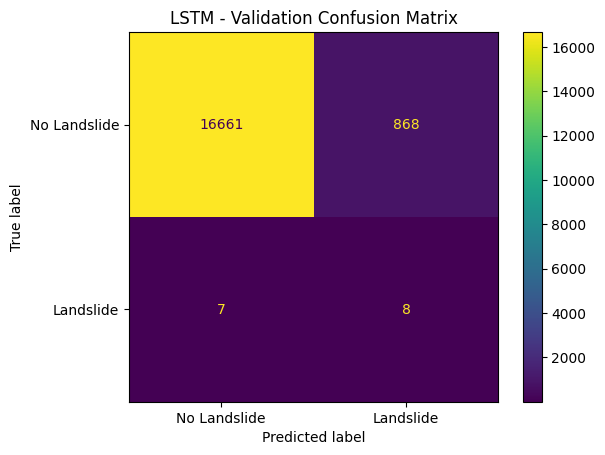

In [37]:
# ============================================================
# CELL 33 - LSTM VALIDATION CONFUSION MATRIX
# ============================================================

cm_lstm_val = confusion_matrix(
    y_lstm_val,
    lstm_tuned_val_pred
)

print(cm_lstm_val)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lstm_val,
    display_labels=[
        "No Landslide",
        "Landslide"
    ]
)

disp.plot()

plt.title(
    "LSTM - Validation Confusion Matrix"
)

plt.show()

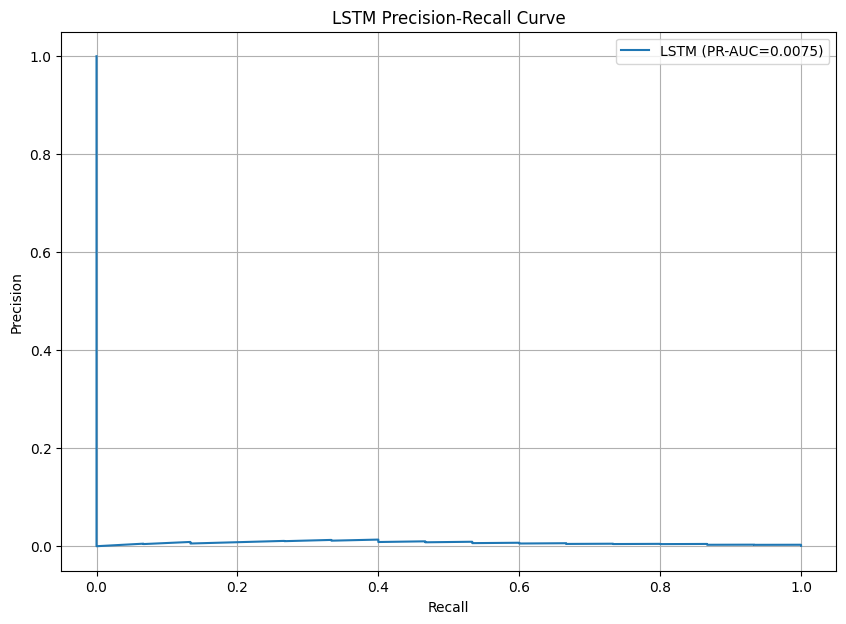

In [38]:
# ============================================================
# CELL 34 - LSTM PR CURVE
# ============================================================

precision_lstm, recall_lstm, _ = (
    precision_recall_curve(
        y_lstm_val,
        lstm_val_prob
    )
)

plt.figure(figsize=(10, 7))

plt.plot(
    recall_lstm,
    precision_lstm,
    label=f"LSTM (PR-AUC={lstm_val_pr_auc:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "LSTM Precision-Recall Curve"
)

plt.legend()
plt.grid(True)

plt.show()

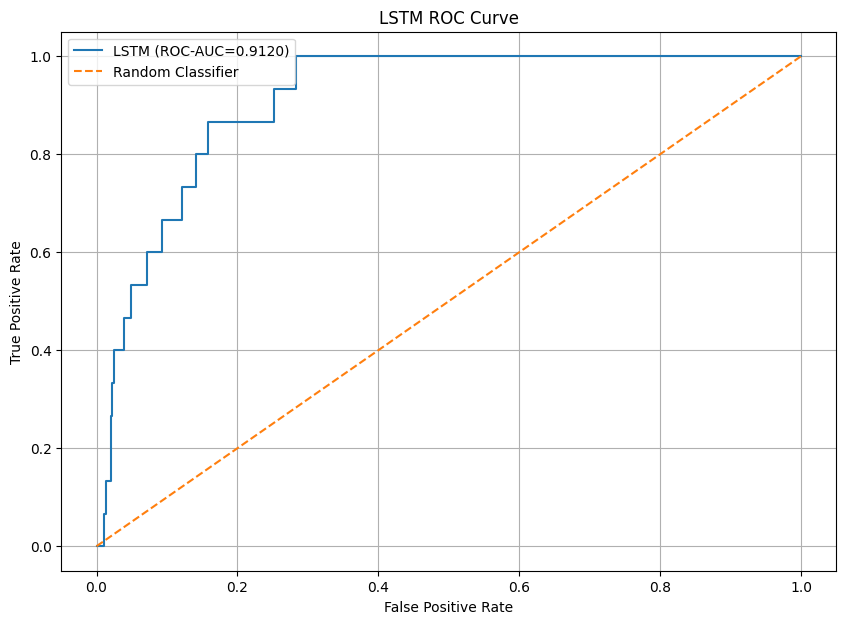

In [39]:
# ============================================================
# CELL 35 - LSTM ROC CURVE
# ============================================================

fpr_lstm, tpr_lstm, _ = roc_curve(
    y_lstm_val,
    lstm_val_prob
)

plt.figure(figsize=(10, 7))

plt.plot(
    fpr_lstm,
    tpr_lstm,
    label=f"LSTM (ROC-AUC={lstm_val_roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "LSTM ROC Curve"
)

plt.legend()
plt.grid(True)

plt.show()

In [40]:
# ============================================================
# CELL 36 - LSTM TEST PREDICTIONS
# ============================================================

y_lstm_test, lstm_test_prob = predict_probabilities(
    lstm_model,
    test_loader,
    DEVICE
)

lstm_test_pred = (
    lstm_test_prob >= best_lstm_threshold
).astype(int)

print("LSTM test predictions created.")

LSTM test predictions created.


In [41]:
# ============================================================
# CELL 37 - FINAL LSTM TEST RESULTS
# ============================================================

lstm_test_accuracy = accuracy_score(
    y_lstm_test,
    lstm_test_pred
)

lstm_test_precision = precision_score(
    y_lstm_test,
    lstm_test_pred,
    zero_division=0
)

lstm_test_recall = recall_score(
    y_lstm_test,
    lstm_test_pred,
    zero_division=0
)

lstm_test_f1 = f1_score(
    y_lstm_test,
    lstm_test_pred,
    zero_division=0
)

lstm_test_roc_auc = roc_auc_score(
    y_lstm_test,
    lstm_test_prob
)

lstm_test_pr_auc = average_precision_score(
    y_lstm_test,
    lstm_test_prob
)

print("FINAL LSTM TEST RESULTS")
print("=" * 60)

print("Accuracy :", lstm_test_accuracy)
print("Precision:", lstm_test_precision)
print("Recall   :", lstm_test_recall)
print("F1       :", lstm_test_f1)
print("ROC-AUC  :", lstm_test_roc_auc)
print("PR-AUC   :", lstm_test_pr_auc)

FINAL LSTM TEST RESULTS
Accuracy : 0.9226027397260274
Precision: 0.01692420897718911
Recall   : 0.5348837209302325
F1       : 0.03281027104136947
ROC-AUC  : 0.9011471555306576
PR-AUC   : 0.021189118105850193


In [42]:
# ============================================================
# CELL 38 - LSTM TEST CLASSIFICATION REPORT
# ============================================================

print(
    classification_report(
        y_lstm_test,
        lstm_test_pred,
        target_names=[
            "No Landslide",
            "Landslide"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

No Landslide       1.00      0.92      0.96     17477
   Landslide       0.02      0.53      0.03        43

    accuracy                           0.92     17520
   macro avg       0.51      0.73      0.50     17520
weighted avg       1.00      0.92      0.96     17520



Confusion Matrix:
[[16141  1336]
 [   20    23]]


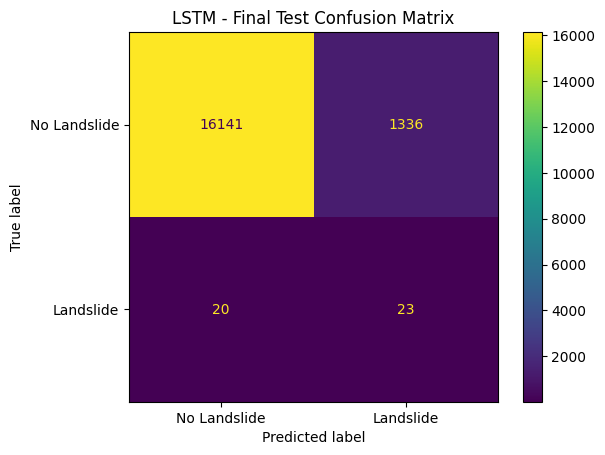

In [43]:
# ============================================================
# CELL 39 - LSTM TEST CONFUSION MATRIX
# ============================================================

cm_lstm_test = confusion_matrix(
    y_lstm_test,
    lstm_test_pred
)

print("Confusion Matrix:")
print(cm_lstm_test)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lstm_test,
    display_labels=[
        "No Landslide",
        "Landslide"
    ]
)

disp.plot()

plt.title(
    "LSTM - Final Test Confusion Matrix"
)

plt.show()

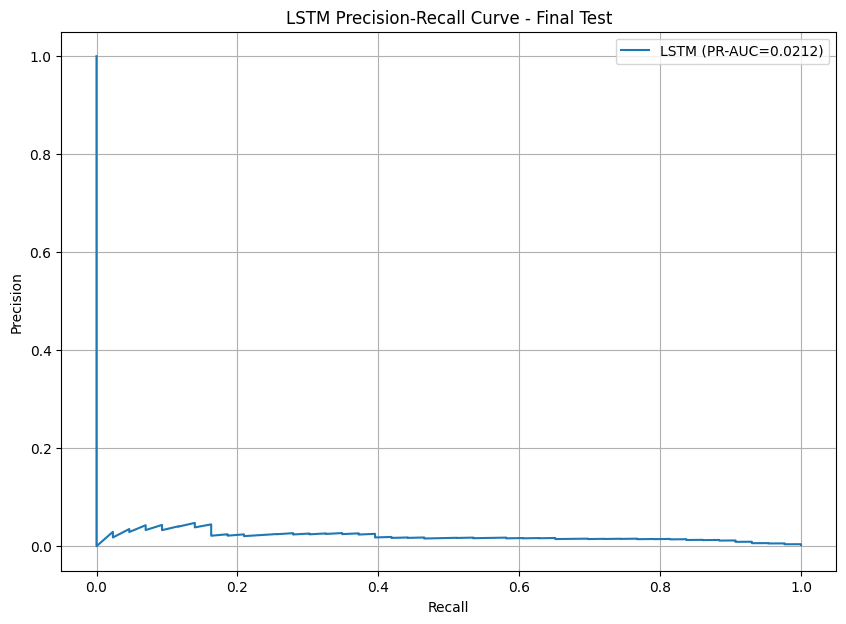

In [44]:
# ============================================================
# CELL 40 - LSTM FINAL TEST PR CURVE
# ============================================================

test_precision_lstm, test_recall_lstm, _ = (
    precision_recall_curve(
        y_lstm_test,
        lstm_test_prob
    )
)

plt.figure(figsize=(10, 7))

plt.plot(
    test_recall_lstm,
    test_precision_lstm,
    label=f"LSTM (PR-AUC={lstm_test_pr_auc:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "LSTM Precision-Recall Curve - Final Test"
)

plt.legend()
plt.grid(True)

plt.show()

In [45]:
# ============================================================
# CELL 41 - COMPLETE MODEL COMPARISON
# ============================================================

# ------------------------------------------------------------
# Results from 06_train_models.ipynb
# ------------------------------------------------------------

logistic_test_results = {
    "Model": "Logistic Regression - Final Test",
    "Accuracy": 0.7952625570776256,
    "Precision": 0.011037527593818985,
    "Recall": 0.9302325581395349,
    "F1": 0.0218161985274066,
    "ROC_AUC": 0.9275220189724435,
    "PR_AUC": 0.026140305186082895
}

rf_test_results = {
    "Model": "Random Forest - Final Test",
    "Accuracy": 0.954851598173516,
    "Precision": 0.025380710659898477,
    "Recall": 0.46511627906976744,
    "F1": 0.048134777376654635,
    "ROC_AUC": 0.8687051819600777,
    "PR_AUC": 0.024142399444423847
}

xgb_test_results = {
    "Model": "XGBoost - Final Test",
    "Accuracy": 0.9375,
    "Precision": 0.02355072463768116,
    "Recall": 0.6046511627906976,
    "F1": 0.045335658238884045,
    "ROC_AUC": 0.9134477073522542,
    "PR_AUC": 0.027840922345476103
}

# ------------------------------------------------------------
# LSTM Final Test Results
# ------------------------------------------------------------

lstm_test_results = {
    "Model": "LSTM - Final Test",
    "Accuracy": lstm_test_accuracy,
    "Precision": lstm_test_precision,
    "Recall": lstm_test_recall,
    "F1": lstm_test_f1,
    "ROC_AUC": lstm_test_roc_auc,
    "PR_AUC": lstm_test_pr_auc
}

# ------------------------------------------------------------
# Combine all models
# ------------------------------------------------------------

complete_model_comparison = pd.DataFrame([
    logistic_test_results,
    rf_test_results,
    xgb_test_results,
    lstm_test_results
])

display(complete_model_comparison)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression - Final Test,0.795263,0.011038,0.930233,0.021816,0.927522,0.026140
1,Random Forest - Final Test,0.954852,0.025381,0.465116,0.048135,0.868705,0.024142
2,XGBoost - Final Test,0.937500,0.023551,0.604651,0.045336,0.913448,0.027841
3,LSTM - Final Test,0.922603,0.016924,0.534884,0.032810,0.901147,0.021189


In [52]:
# ============================================================
# COMPLETE FINAL TEST MODEL COMPARISON
# ============================================================

final_model_comparison = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
        "LSTM"
    ],

    "Accuracy": [
        accuracy_score(
            y_test_previous,
            np.load(
                os.path.join(
                    comparison_dir,
                    "logistic_test_pred.npy"
                )
            )
        ),

        accuracy_score(
            y_test_previous,
            np.load(
                os.path.join(
                    comparison_dir,
                    "rf_test_pred.npy"
                )
            )
        ),

        accuracy_score(
            y_test_previous,
            np.load(
                os.path.join(
                    comparison_dir,
                    "xgb_test_pred.npy"
                )
            )
        ),

        lstm_test_accuracy
    ],

    "Precision": [
        precision_score(
            y_test_previous,
            np.load(
                os.path.join(
                    comparison_dir,
                    "logistic_test_pred.npy"
                )
            ),
            zero_division=0
        ),

        precision_score(
            y_test_previous,
            np.load(
                os.path.join(
                    comparison_dir,
                    "rf_test_pred.npy"
                )
            ),
            zero_division=0
        ),

        precision_score(
            y_test_previous,
            np.load(
                os.path.join(
                    comparison_dir,
                    "xgb_test_pred.npy"
                )
            ),
            zero_division=0
        ),

        lstm_test_precision
    ],

    "Recall": [
        recall_score(
            y_test_previous,
            np.load(
                os.path.join(
                    comparison_dir,
                    "logistic_test_pred.npy"
                )
            ),
            zero_division=0
        ),

        recall_score(
            y_test_previous,
            np.load(
                os.path.join(
                    comparison_dir,
                    "rf_test_pred.npy"
                )
            ),
            zero_division=0
        ),

        recall_score(
            y_test_previous,
            np.load(
                os.path.join(
                    comparison_dir,
                    "xgb_test_pred.npy"
                )
            ),
            zero_division=0
        ),

        lstm_test_recall
    ],

    "F1": [
        f1_score(
            y_test_previous,
            np.load(
                os.path.join(
                    comparison_dir,
                    "logistic_test_pred.npy"
                )
            ),
            zero_division=0
        ),

        f1_score(
            y_test_previous,
            np.load(
                os.path.join(
                    comparison_dir,
                    "rf_test_pred.npy"
                )
            ),
            zero_division=0
        ),

        f1_score(
            y_test_previous,
            np.load(
                os.path.join(
                    comparison_dir,
                    "xgb_test_pred.npy"
                )
            ),
            zero_division=0
        ),

        lstm_test_f1
    ],

    "ROC_AUC": [
        roc_auc_score(
            y_test_previous,
            logistic_test_prob_previous
        ),

        roc_auc_score(
            y_test_previous,
            rf_test_prob_previous
        ),

        roc_auc_score(
            y_test_previous,
            xgb_test_prob_previous
        ),

        lstm_test_roc_auc
    ],

    "PR_AUC": [
        pr_auc_lr,
        pr_auc_rf,
        pr_auc_xgb,
        lstm_test_pr_auc
    ]
})

display(
    final_model_comparison
)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.795263,0.011038,0.930233,0.021816,0.927522,0.026140
1,Random Forest,0.954852,0.025381,0.465116,0.048135,0.868705,0.024142
2,XGBoost,0.937500,0.023551,0.604651,0.045336,0.913448,0.027841
3,LSTM,0.922603,0.016924,0.534884,0.032810,0.901147,0.021189


In [53]:
# ============================================================
# CELL 42 - SORT MODELS
# ============================================================

comparison_sorted = complete_model_comparison.sort_values(
    "PR_AUC",
    ascending=False
)

display(comparison_sorted)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
2,XGBoost,0.937500,0.023551,0.604651,0.045336,0.913448,0.027841
0,Logistic Regression,0.795263,0.011038,0.930233,0.021816,0.927522,0.026140
1,Random Forest,0.954852,0.025381,0.465116,0.048135,0.868705,0.024142
3,LSTM,0.922603,0.016924,0.534884,0.032810,0.901147,0.021189


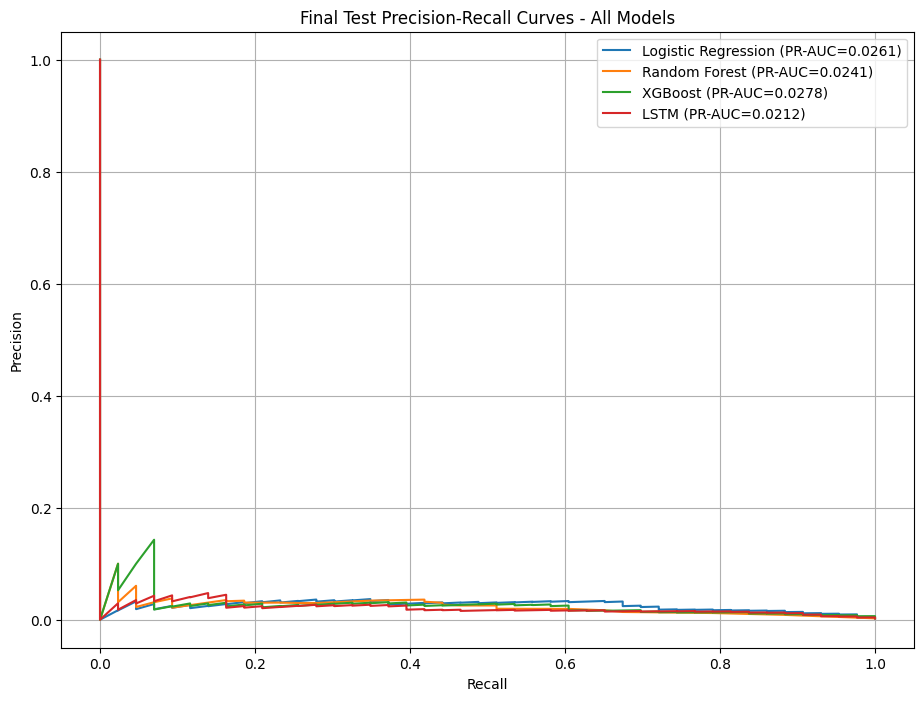

In [50]:
# ============================================================
# CELL 43 - ALL MODEL PR CURVES
# ============================================================

plt.figure(figsize=(11, 8))

# ------------------------------------------------------------
# Logistic Regression
# ------------------------------------------------------------

precision_lr, recall_lr, _ = precision_recall_curve(
    y_test_previous,
    logistic_test_prob_previous
)

pr_auc_lr = average_precision_score(
    y_test_previous,
    logistic_test_prob_previous
)

plt.plot(
    recall_lr,
    precision_lr,
    label=f"Logistic Regression (PR-AUC={pr_auc_lr:.4f})"
)


# ------------------------------------------------------------
# Random Forest
# ------------------------------------------------------------

precision_rf, recall_rf, _ = precision_recall_curve(
    y_test_previous,
    rf_test_prob_previous
)

pr_auc_rf = average_precision_score(
    y_test_previous,
    rf_test_prob_previous
)

plt.plot(
    recall_rf,
    precision_rf,
    label=f"Random Forest (PR-AUC={pr_auc_rf:.4f})"
)


# ------------------------------------------------------------
# XGBoost
# ------------------------------------------------------------

precision_xgb, recall_xgb, _ = precision_recall_curve(
    y_test_previous,
    xgb_test_prob_previous
)

pr_auc_xgb = average_precision_score(
    y_test_previous,
    xgb_test_prob_previous
)

plt.plot(
    recall_xgb,
    precision_xgb,
    label=f"XGBoost (PR-AUC={pr_auc_xgb:.4f})"
)


# ------------------------------------------------------------
# LSTM
# ------------------------------------------------------------

precision_lstm, recall_lstm, _ = precision_recall_curve(
    y_lstm_test,
    lstm_test_prob
)

pr_auc_lstm = average_precision_score(
    y_lstm_test,
    lstm_test_prob
)

plt.plot(
    recall_lstm,
    precision_lstm,
    label=f"LSTM (PR-AUC={pr_auc_lstm:.4f})"
)


# ------------------------------------------------------------
# Plot settings
# ------------------------------------------------------------

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Final Test Precision-Recall Curves - All Models"
)

plt.legend()

plt.grid(True)

plt.show()

In [51]:
# ============================================================
# VERIFY FINAL TEST PR-AUC VALUES
# ============================================================

final_pr_auc_check = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
        "LSTM"
    ],

    "PR_AUC": [
        pr_auc_lr,
        pr_auc_rf,
        pr_auc_xgb,
        pr_auc_lstm
    ]
})

display(
    final_pr_auc_check.sort_values(
        "PR_AUC",
        ascending=False
    )
)

,Model,PR_AUC
2,XGBoost,0.027841
0,Logistic Regression,0.026140
1,Random Forest,0.024142
3,LSTM,0.021189


In [54]:
# ============================================================
# CELL 44 - SAVE MODEL COMPARISON
# ============================================================

comparison_file = os.path.join(
    BASE_DIR,
    "data",
    "processed",
    "final_model_comparison.csv"
)

complete_model_comparison.to_csv(
    comparison_file,
    index=False
)

print(
    "Comparison saved to:"
)

print(comparison_file)

Comparison saved to:
..\data\processed\final_model_comparison.csv


In [55]:
# ============================================================
# CELL 45 - SAVE LSTM SCALER
# ============================================================

scaler_path = os.path.join(
    MODEL_DIR,
    "lstm_scaler.pkl"
)

joblib.dump(
    scaler,
    scaler_path
)

print(
    "Scaler saved:"
)

print(scaler_path)

Scaler saved:
..\models\lstm_scaler.pkl


In [56]:
# ============================================================
# CELL 46 - SAVE LSTM CONFIGURATION
# ============================================================

lstm_config = {

    "sequence_length": SEQUENCE_LENGTH,

    "features": LSTM_FEATURES,

    "target": TARGET,

    "hidden_size": 64,

    "num_layers": 2,

    "dropout": 0.3,

    "best_threshold": float(
        best_lstm_threshold
    ),

    "model_start": MODEL_START,

    "train_end": TRAIN_END,

    "validation_start": VAL_START,

    "validation_end": VAL_END,

    "test_start": TEST_START
}

config_path = os.path.join(
    MODEL_DIR,
    "lstm_config.pkl"
)

joblib.dump(
    lstm_config,
    config_path
)

print(
    "LSTM configuration saved:"
)

print(config_path)

LSTM configuration saved:
..\models\lstm_config.pkl


In [57]:
# ============================================================
# CELL 47 - VERIFY SAVED FILES
# ============================================================

print("Files in models directory:\n")

for file in sorted(
    os.listdir(MODEL_DIR)
):

    print(file)

Files in models directory:

feature_columns.pkl
logistic_landslide_model.pkl
logistic_regression_balanced.pkl
lstm_config.pkl
lstm_landslide_best.pth
lstm_scaler.pkl
model_thresholds.pkl
random_forest_balanced.pkl
random_forest_landslide_model.pkl
xgboost_landslide_model.pkl


In [58]:
# ============================================================
# CELL 48 - PACKAGE FINAL MODEL FOR DEPLOYMENT
# ============================================================

import os
import joblib
import json
import pandas as pd

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

MODEL_DIR = "../models"
PROCESSED_DIR = "../data/processed"

os.makedirs(MODEL_DIR, exist_ok=True)

# ------------------------------------------------------------
# 2. Final deployment model
# ------------------------------------------------------------

FINAL_MODEL_NAME = "XGBoost"

FINAL_MODEL_SOURCE = os.path.join(
    MODEL_DIR,
    "xgboost_landslide_model.pkl"
)

FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "lankalandslide_final_model.pkl"
)

# Load trained XGBoost model
final_model = joblib.load(FINAL_MODEL_SOURCE)

# Save a clean deployment copy
joblib.dump(
    final_model,
    FINAL_MODEL_PATH
)

print("Final deployment model saved:")
print(FINAL_MODEL_PATH)

# ------------------------------------------------------------
# 3. Load feature columns
# ------------------------------------------------------------

FEATURE_COLUMNS_PATH = os.path.join(
    MODEL_DIR,
    "feature_columns.pkl"
)

feature_columns = joblib.load(FEATURE_COLUMNS_PATH)

print("\nNumber of features:", len(feature_columns))

print("\nFeatures:")
for i, feature in enumerate(feature_columns, start=1):
    print(f"{i}. {feature}")

# ------------------------------------------------------------
# 4. Save deployment feature list
# ------------------------------------------------------------

DEPLOYMENT_FEATURES_PATH = os.path.join(
    MODEL_DIR,
    "deployment_feature_columns.json"
)

with open(DEPLOYMENT_FEATURES_PATH, "w") as f:
    json.dump(feature_columns, f, indent=4)

print("\nFeature configuration saved:")
print(DEPLOYMENT_FEATURES_PATH)

# ------------------------------------------------------------
# 5. Load model thresholds
# ------------------------------------------------------------

THRESHOLD_PATH = os.path.join(
    MODEL_DIR,
    "model_thresholds.pkl"
)

model_thresholds = joblib.load(THRESHOLD_PATH)

print("\nSaved model thresholds:")
print(model_thresholds)

# ------------------------------------------------------------
# 6. Extract XGBoost threshold
# ------------------------------------------------------------

xgb_threshold = None

if isinstance(model_thresholds, dict):

    # Try common possible key names
    possible_keys = [
        "xgb",
        "XGBoost",
        "XGBoost - Tuned",
        "xgboost",
        "xgb_threshold",
        "XGBoost_threshold"
    ]

    for key in possible_keys:
        if key in model_thresholds:
            xgb_threshold = model_thresholds[key]
            break

# If threshold is nested inside a dictionary
if isinstance(xgb_threshold, dict):

    for key in ["threshold", "best_threshold", "value"]:
        if key in xgb_threshold:
            xgb_threshold = xgb_threshold[key]
            break

# ------------------------------------------------------------
# 7. Fallback threshold
# ------------------------------------------------------------

if xgb_threshold is None:
    print("\nWARNING: XGBoost tuned threshold was not found.")
    print("Using default threshold = 0.50")
    xgb_threshold = 0.50

xgb_threshold = float(xgb_threshold)

print("\nXGBoost deployment threshold:", xgb_threshold)

# ------------------------------------------------------------
# 8. Create deployment configuration
# ------------------------------------------------------------

deployment_config = {
    "project": "LankaLandslide AI",
    "model_name": "XGBoost",
    "model_type": "XGBClassifier",
    "model_file": "lankalandslide_final_model.pkl",
    "feature_file": "deployment_feature_columns.json",
    "threshold": xgb_threshold,
    "prediction_unit": "district-day",
    "target": "landslide_recorded",
    "training_period": "1998-01-01 to 2019-12-31",
    "test_period": "2018-01-01 to 2019-12-31",
    "note": (
        "This model estimates district-level landslide risk "
        "from weather and terrain features. It is a decision-support "
        "model and is not an official warning system."
    )
}

CONFIG_PATH = os.path.join(
    MODEL_DIR,
    "deployment_config.json"
)

with open(CONFIG_PATH, "w") as f:
    json.dump(
        deployment_config,
        f,
        indent=4
    )

print("\nDeployment configuration saved:")
print(CONFIG_PATH)

# ------------------------------------------------------------
# 9. Final verification
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("DEPLOYMENT PACKAGE VERIFIED")
print("=" * 60)

print("\nModel:")
print(FINAL_MODEL_PATH)

print("\nFeatures:")
print(DEPLOYMENT_FEATURES_PATH)

print("\nThreshold:")
print(xgb_threshold)

print("\nConfiguration:")
print(CONFIG_PATH)

print("\nNumber of features:")
print(len(feature_columns))

print("\nDeployment package is ready.")

Final deployment model saved:
../models\lankalandslide_final_model.pkl

Number of features: 27

Features:
1. rainfall_1day
2. rainfall_3day
3. rainfall_7day
4. rainfall_14day
5. rainfall_30day
6. rainfall_3day_avg
7. rainfall_7day_avg
8. rainfall_14day_avg
9. rainfall_30day_avg
10. rain_hours
11. temp_max
12. temp_min
13. temp_mean
14. temperature_range
15. wind_max
16. wind_gust_max
17. month_sin
18. month_cos
19. heavy_rain_10mm
20. heavy_rain_25mm
21. heavy_rain_50mm
22. heavy_rain_100mm
23. elevation_mean_m
24. elevation_max_m
25. elevation_min_m
26. slope_mean_deg
27. slope_max_deg

Feature configuration saved:
../models\deployment_feature_columns.json

Saved model thresholds:
{'logistic_regression': 0.5, 'random_forest': 0.03, 'xgboost': 0.49}

XGBoost deployment threshold: 0.49

Deployment configuration saved:
../models\deployment_config.json

DEPLOYMENT PACKAGE VERIFIED

Model:
../models\lankalandslide_final_model.pkl

Features:
../models\deployment_feature_columns.json

Thresh